# Illustrating the Differentiable Simulator Pipeline

This notebook breaks down the LUT-based simulation path for a single particle mini-segment. We will visualize:
1. **Transverse Mapping**: How a track position maps to a pixel and its neighbors.
2. **LUT Binning**: How sub-pixel positions select specific current response templates.
3. **Longitudinal Interpolation**: How waveforms are smoothly morphed based on drift distance.
4. **Neighbor Signals**: The difference between collection and induction signals.
5. **Signal Accumulation**: How multiple segments combine into a single pixel waveform.
6. **The `segment_sum` Procedure**: The mapping from many input packets to a unique set of pixels.

In [ ]:
import jax.numpy as jnp
import jax
import matplotlib.pyplot as plt
import numpy as np
from larndsim.consts_jax import Params

# Mocking some parameters for visualization
params = Params()
params.pixel_pitch = 4.43  # mm
params.t_sampling = 0.1    # us
params.signal_length = 60  # ticks
params.nb_sampling_bins_per_pixel = 8 # The Nx, Ny dimensions in our LUT
params.number_pix_neighbors = 1 # 3x3 grid

print(f"Pixel Pitch: {params.pixel_pitch} mm")
print(f"LUT Spatial Resolution: {params.pixel_pitch / params.nb_sampling_bins_per_pixel:.3f} mm/bin")

## 1. Transverse Mapping
When a mini-segment is at a specific $(x, y)$ coordinate, it primarily affects one pixel but induces signals on all neighbors. We use a $3 \times 3$ grid for this illustration.

In [ ]:
def plot_transverse_mapping(x_hit, y_hit, pitch):
    fig, ax = plt.subplots(figsize=(6, 6))
    
    # Draw a 3x3 pixel grid
    for i in range(-1, 2):
        for j in range(-1, 2):
            color = 'blue' if (i == 0 and j == 0) else 'gray'
            alpha = 0.3 if (i == 0 and j == 0) else 0.1
            rect = plt.Rectangle((i*pitch - pitch/2, j*pitch - pitch/2), pitch, pitch, 
                                 fill=True, color=color, alpha=alpha, ec='black', lw=2)
            ax.add_patch(rect)
            label = "Main Pixel" if (i==0 and j==0) else "Neighbor"
            ax.text(i*pitch, j*pitch + pitch/3, label, ha='center', fontsize=9, fontweight='bold')
            ax.text(i*pitch, j*pitch - pitch/3, f"ID: ({i},{j})", ha='center', fontsize=8)

    # Draw the hit point
    ax.scatter([x_hit], [y_hit], color='red', s=150, zorder=5, label="Mini-segment Position")
    ax.quiver([0], [0], [x_hit], [y_hit], angles='xy', scale_units='xy', scale=1, color='red', alpha=0.5)
    
    ax.set_xlim(-pitch*1.7, pitch*1.7)
    ax.set_ylim(-pitch*1.7, pitch*1.7)
    ax.set_aspect('equal')
    ax.set_title("Step 1: Track-to-Pixel Mapping")
    ax.set_xlabel("x [mm]")
    ax.set_ylabel("y [mm]")
    ax.legend(loc='upper right')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()

# Define a hit that is slightly off-center
x_pos, y_pos = 1.2, -0.8
plot_transverse_mapping(x_pos, y_pos, params.pixel_pitch)

## 2. LUT Spatial Binning
The 4D LUT has spatial dimensions $(Nx, Ny)$ that represent sub-pixel positions. The simulator calculates which "bin" the charge falls into. For neighbor pixels, this binning is offset by the pixel pitch.

In [ ]:
def illustrate_lut_bins(x_hit, y_hit, params):
    # Convert mm to bin index
    bin_width = params.pixel_pitch / params.nb_sampling_bins_per_pixel
    # Central pixel bin calculation
    ix = int(np.abs(x_hit % params.pixel_pitch - params.pixel_pitch/2 + 0.5*bin_width) / bin_width)
    iy = int(np.abs(y_hit % params.pixel_pitch - params.pixel_pitch/2 + 0.5*bin_width) / bin_width)
    
    print(f"Hit at ({x_hit}, {y_hit}) mm")
    print(f"Selected LUT Spatial Bin for Main Pixel: (Nx={ix}, Ny={iy})")
    
    # Visualizing the 8x8 LUT spatial grid within the main pixel
    fig, ax = plt.subplots(figsize=(5, 5))
    grid = np.zeros((params.nb_sampling_bins_per_pixel, params.nb_sampling_bins_per_pixel))
    grid[ix, iy] = 1
    
    im = ax.imshow(grid.T, origin='lower', extent=[-params.pixel_pitch/2, params.pixel_pitch/2, 
                                                  -params.pixel_pitch/2, params.pixel_pitch/2])
    ax.set_title("Sub-pixel LUT Bin Selection (8x8 Grid)")
    ax.set_xlabel("Local x [mm]")
    ax.set_ylabel("Local y [mm]")
    plt.colorbar(im, label="Selected Bin")
    plt.show()

illustrate_lut_bins(x_pos, y_pos, params)

## 3. Longitudinal Interpolation
The simulator interpolates between pre-computed templates in the LUT to handle varying drift distances (diffusion levels) differentiably.

In [ ]:
def plot_interpolation(diffusion_val):
    t = jnp.linspace(0, 10, 100)
    # Mock templates: narrow (0), medium (1), wide (2)
    temp0 = jnp.exp(-(t-5)**2 / 0.5)
    temp1 = jnp.exp(-(t-5)**2 / 1.5)
    temp2 = jnp.exp(-(t-5)**2 / 3.0)
    
    # Simple quadratic interpolation weights for illustration
    # In the real code, this is calculated via searchsorted and params.long_diff_template
    w0, w1, w2 = 0.1, 0.7, 0.2 
    interpolated = w0*temp0 + w1*temp1 + w2*temp2
    
    plt.figure(figsize=(10, 4))
    plt.plot(t, temp0, 'k--', alpha=0.3, label="Low Diffusion Template")
    plt.plot(t, temp1, 'k--', alpha=0.6, label="Mid Diffusion Template")
    plt.plot(t, temp2, 'k--', alpha=0.3, label="High Diffusion Template")
    plt.plot(t, interpolated, 'r-', lw=3, label="Differentiable Result")
    
    plt.title("Step 3: Longitudinal Interpolation")
    plt.xlabel("Time [us]")
    plt.ylabel("Induced Current")
    plt.legend()
    plt.show()

plot_interpolation(0.7)

## 4. Collection vs. Induction Signals
Finally, we visualize the total signal. The main pixel receives the **collection** signal (electrons landing), while neighbors receive the **induction** signal (bipolar, as electrons pass by).

In [ ]:
def plot_final_signals():
    t = jnp.linspace(0, 20, 200)
    
    # Collection: unipolar pulse
    collection = jnp.exp(-(t-10)**2 / 1.0)
    
    # Induction: bipolar pulse (Shockley-Ramo)
    # Derivative of a Gaussian is a common approximation for induction
    induction = -2 * (t-10) * jnp.exp(-(t-10)**2 / 1.5)
    
    plt.figure(figsize=(10, 5))
    plt.plot(t, collection, 'b-', label="Main Pixel (Collection)", lw=2)
    plt.plot(t, 0.3 * induction, 'g--', label="Neighbor Pixel (Induction)", lw=2)
    
    plt.axhline(0, color='black', lw=0.5)
    plt.fill_between(t, collection, alpha=0.1, color='blue')
    plt.fill_between(t, 0.3 * induction, alpha=0.1, color='green')
    
    plt.title("Final Step: Current Waveforms on Pixel Grid")
    plt.xlabel("Time [us]")
    plt.ylabel("Current [A.U.]")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_final_signals()

## 5. Signal Accumulation (`segment_sum`)
In a real event, a single pixel receives charge from many mini-segments. The simulator uses `jax.ops.segment_sum` to accumulate these contributions into a single waveform in a differentiable and GPU-efficient way.

In [ ]:
def plot_accumulation():
    t = jnp.linspace(0, 30, 300)
    
    # Three different mini-segments hitting the same pixel
    # Each has a different arrival time (t0) and charge (amplitude)
    sig1 = 1.0 * jnp.exp(-(t-10)**2 / 1.0)
    sig2 = 0.6 * jnp.exp(-(t-12)**2 / 1.2)
    sig3 = 0.8 * jnp.exp(-(t-15)**2 / 0.8)
    
    # The 'segment_sum' result
    total_wf = sig1 + sig2 + sig3
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
    
    # Plot individual contributions
    ax1.plot(t, sig1, label="Segment A", lw=2, alpha=0.7)
    ax1.plot(t, sig2, label="Segment B", lw=2, alpha=0.7)
    ax1.plot(t, sig3, label="Segment C", lw=2, alpha=0.7)
    ax1.set_title("Individual Mini-Segment Contributions to One Pixel")
    ax1.set_ylabel("Induced Current")
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Plot the accumulated result
    ax2.plot(t, total_wf, color='purple', lw=3, label="Final Waveform (sum)")
    ax2.fill_between(t, total_wf, color='purple', alpha=0.2)
    ax2.set_title("Accumulated Result (via jax.ops.segment_sum)")
    ax2.set_xlabel("Time [us]")
    ax2.set_ylabel("Total Current")
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

plot_accumulation()

## 6. The `segment_sum` Procedure: Many-to-One Mapping
This diagram illustrates how thousands of independent mini-segments are mapped and summed into a smaller, unique set of active pixels. This is the core of our parallelized waveform generation.

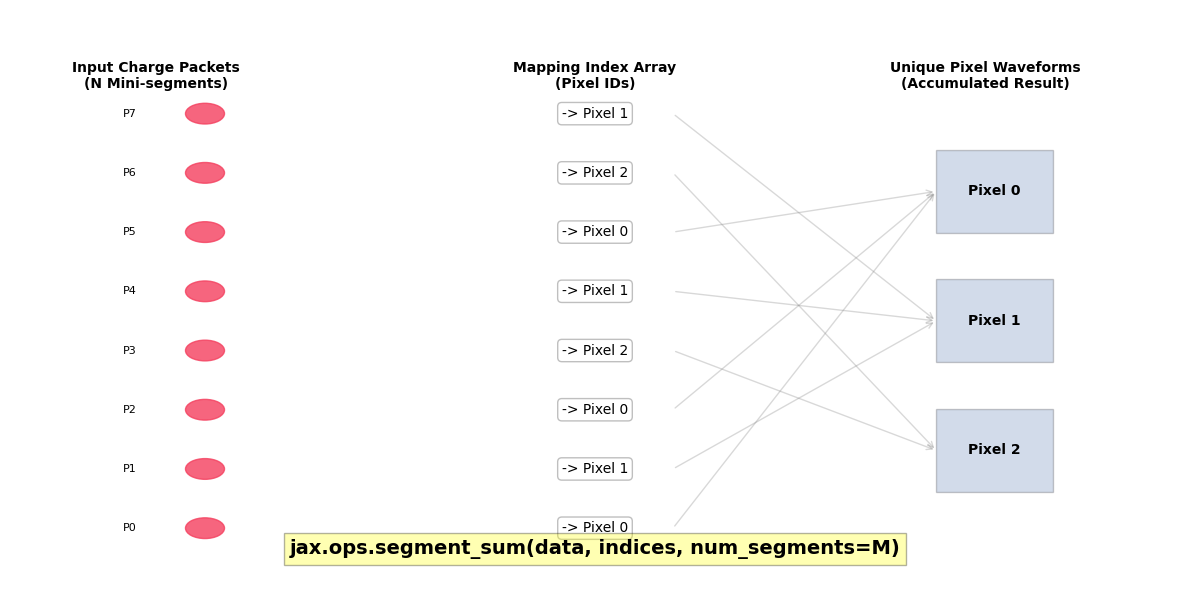

In [67]:
def plot_segment_sum_logic():
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # 1. Draw Input Packets (Many)
    n_packets = 8
    packet_y = np.linspace(0.1, 0.9, n_packets)
    ax.text(0.05, 0.95, "Input Charge Packets\n(N Mini-segments)", ha='center', fontweight='bold')
    for i, y in enumerate(packet_y):
        ax.add_patch(plt.Circle((0.1, y), 0.02, color='#f43f5e', alpha=0.8))
        ax.text(0.03, y, f"P{i}", ha='right', va='center', fontsize=8)
    
    # 2. Draw Mapping Indices
    ax.text(0.5, 0.95, "Mapping Index Array\n(Pixel IDs)", ha='center', fontweight='bold')
    indices = [0, 1, 0, 2, 1, 0, 2, 1]
    for i, (y, idx) in enumerate(zip(packet_y, indices)):
        ax.text(0.5, y, f"-> Pixel {idx}", ha='center', va='center', 
                bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.5))
        # Draw Arrows
        target_y = [0.75, 0.5, 0.25][idx]
        ax.annotate("", xy=(0.85, target_y), xytext=(0.58, y), 
                    arrowprops=dict(arrowstyle="->", color='gray', alpha=0.3))
    
    # 3. Draw Output Buckets (Unique Pixels)
    ax.text(0.9, 0.95, "Unique Pixel Waveforms\n(Accumulated Result)", ha='center', fontweight='bold')
    bucket_labels = ["Pixel 0", "Pixel 1", "Pixel 2"]
    bucket_y = [0.75, 0.5, 0.25]
    for label, y in zip(bucket_labels, bucket_y):
        rect = plt.Rectangle((0.85, y-0.08), 0.12, 0.16, fill=True, color='#1f4b99', alpha=0.2, ec='black')
        ax.add_patch(rect)
        ax.text(0.91, y, label, ha='center', va='center', fontweight='bold')
        
    # Add a big label for the operation
    ax.text(0.5, 0.05, "jax.ops.segment_sum(data, indices, num_segments=M)", 
            ha='center', fontsize=14, fontweight='bold', bbox=dict(facecolor='yellow', alpha=0.3))
    
    ax.set_axis_off()
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(0, 1.1)
    plt.tight_layout()
    plt.show()

plot_segment_sum_logic()